# 🛡️ EconoCausal Walkthrough 04: Causal Refutations, Sensitivity Analysis & Real-Time Drift Telemetry

**EconoCausal Production Walkthrough Series**  
*Causal Inference Engine for E-Commerce & Retail Promotion Optimization*

---

## 🎯 Objectives
In this final walkthrough notebook, we establish the **production reliability & governance framework** for causal models:
1. **The Silent Failure Problem**: Why causal models require specialized robustness verification beyond predictive metrics (AUC / RMSE).
2. **DoWhy Invariance & Refutation Tests**: Execute Placebo Treatment, Random Common Cause, and Data Subset refutations.
3. **Sensitivity Analysis & Robustness Bounds**:
   - **Rosenbaum Sensitivity Bounds ($\Gamma$)**: Quantify how much unobserved bias is needed to overturn conclusions.
   - **Cinelli & Hazlett Partial $R^2$**: Plot robustness contours showing unobserved confounder strength thresholds.
   - **Break-Even Profit Resilience**: Calculate the critical bias that would reduce net campaign profit to zero.
4. **Real-Time Data Drift Telemetry**: Simulate 30 days of incoming production streaming traffic with seasonal shifts and macroeconomic shocks.
5. **Continuous Monitoring & Retraining Triggers**: Track rolling **Population Stability Index (PSI)**, **Wasserstein Distance**, and **Kolmogorov-Smirnov (KS)** statistics to trigger automated retraining alerts.


In [1]:
import sys
from pathlib import Path

# Add project root to path for local src module imports
for candidate in [Path(".").resolve(), Path("..").resolve(), Path("../..").resolve()]:
    if (candidate / "src").exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# EconoCausal library imports
from src.data_gen import generate_data
from src.causal_model import (
    build_dag,
    identify_effect,
    run_all_refutations,
    compute_rosenbaum_bounds,
    compute_cinelli_hazlett_robustness,
    compute_sensitivity_suite
)
from src.optimizer import (
    calculate_psi,
    calculate_ks,
    calculate_wasserstein,
    simulate_traffic_stream,
    compute_rolling_drift,
    evaluate_drift
)

# Plotting configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("EconoCausal refutation & telemetry engines ready.")


C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


EconoCausal refutation & telemetry engines ready.


## 1. Baseline Observational Campaign Data

We generate a benchmark cohort of $N = 3,000$ observational customers to serve as our reference distribution for both causal identification and downstream drift tracking.


In [2]:
reference_df = generate_data(n=3000, seed=42)
print(f"Reference cohort generated: {reference_df.shape[0]:,} records")
reference_df[['past_spend', 'recency_days', 'loyalty_tier', 'category_affinity', 'discount', 'purchase']].head(5)


Reference cohort generated: 3,000 records


,past_spend,recency_days,loyalty_tier,category_affinity,discount,purchase
0,119.44,194,Gold,0.1822,20,0
1,53.30,352,Bronze,0.5515,10,0
2,156.06,26,Bronze,0.5118,20,0
3,174.92,298,Silver,0.7965,20,1
4,30.86,197,Bronze,0.5251,20,0


## 2. DoWhy Causal Refutation Suite

Refutation tests are the **unit tests of causal inference**. If an identification strategy is valid, it must pass three rigorous stress tests:
1. **Placebo Treatment**: Replace treatment $T$ with an independent random variable. The estimated effect must collapse to 0.
2. **Random Common Cause**: Add an artificial, independent confounder to the dataset. The estimated effect must remain stable.
3. **Data Subset**: Re-estimate on random 80% bootstrap subsets. The effect estimate should remain statistically indistinguishable.


In [3]:
print("Running DoWhy Causal Refutation Suite across identification pipeline...")
causal_model = build_dag(reference_df, treatment='discount', outcome='purchase')
identified_estimand = identify_effect(causal_model)
estimate = causal_model.estimate_effect(identified_estimand, method_name="backdoor.linear_regression")

# Run refutation suite using src.causal_model.run_all_refutations
refutation_results = run_all_refutations(causal_model, identified_estimand, estimate, random_state=42)

refute_records = []
for test_key in ['placebo', 'random_common_cause', 'data_subset']:
    if test_key in refutation_results:
        res = refutation_results[test_key]
        metric_info = f"p={res.get('p_value', 0.0):.3f}" if 'p_value' in res else f"drift={res.get('drift_percent', 0.0):.1f}%"
        refute_records.append({
            'Refutation Test': res.get('test', test_key).replace('_', ' ').title(),
            'Original Effect': round(res.get('original_effect', 0.0), 4),
            'New Effect Under Refutation': round(res.get('new_effect', 0.0), 4),
            'Metric / Tolerance': metric_info,
            'Verdict': 'PASSED' if res.get('passed', False) else 'FAILED'
        })

refute_df = pd.DataFrame(refute_records)
display(refute_df)


Running DoWhy Causal Refutation Suite across identification pipeline...


C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimator.py:266: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_effect_mods = data.groupby(effect_modifier_names)
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys wi

C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimator.py:266: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_effect_mods = data.groupby(effect_modifier_names)
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys wi

C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_estimators\regression_estimator.py:131: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  intercept_parameter = self.model.params[0]
C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\dowhy\causal_refuter.py:161: RuntimeWarning: divide by zero encountered in scalar divide
  z_score = (estimate.value - mean_refute_values) / std_dev_refute_v

,Refutation Test,Original Effect,New Effect Under Refutation,Metric / Tolerance,Verdict
0,Placebo Treatment,0.0000,-0.0006,p=0.000,PASSED
1,Random Common Cause,0.0077,0.0077,drift=0.0%,PASSED
2,Data Subset,0.0077,0.0078,drift=1.2%,PASSED


## 3. Confounder Sensitivity Analysis & Robustness Bounds

What if there are unmeasured confounders (e.g., consumer price sensitivity or competitor promotions)? We quantify the resilience of our causal estimates using **Rosenbaum Bounds** and **Cinelli-Hazlett Partial $R^2$**.

### Rosenbaum Sensitivity Bounds ($\Gamma$)
The parameter $\Gamma \ge 1$ measures the degree of unobserved selection bias:
$$\frac{1}{\Gamma} \le \frac{P(T=1 \mid X, u) / P(T=0 \mid X, u)}{P(T=1 \mid X, u') / P(T=0 \mid X, u')} \le \Gamma$$
A high **Critical $\Gamma^*$** indicates that extreme unobserved bias would be needed to overturn the treatment effect.


In [4]:
# Compute full sensitivity suite using src.causal_model.compute_sensitivity_suite
sens_suite = compute_sensitivity_suite(
    df=reference_df,
    treatment_col='discount',
    outcome_col='purchase',
    net_profit=4250.0,
    unit_margin=45.0,
    n_treated=350
)

rosen = sens_suite['rosenbaum']
cinelli = sens_suite['cinelli_hazlett']
profit_sens = sens_suite['profit_break_even']

print(f"Overall Unconfoundedness Score: {sens_suite['unconfoundedness_score']}/100")
print(f"Verdict: {sens_suite['verdict']}")
print(f"Critical Rosenbaum Gamma: {rosen['critical_gamma']} (Can withstand {rosen['critical_gamma']}x odds multiplier)")
print(f"Cinelli-Hazlett Robustness Value (Point): {cinelli['robustness_value_point']:.3f}")
print(f"Break-Even Profit Resilience: {profit_sens['robustness_margin']} (Critical Bias: {profit_sens['critical_bias_percent']}%)")


Overall Unconfoundedness Score: 99.0/100
Verdict: Robust to Moderate & Severe Unobserved Confounding
Critical Rosenbaum Gamma: 13.96 (Can withstand 13.96x odds multiplier)
Cinelli-Hazlett Robustness Value (Point): 0.117
Break-Even Profit Resilience: Highly Resilient (Critical Bias: 235.26%)


In [5]:
# Display Rosenbaum Gamma Bounds Table
gamma_df = pd.DataFrame(rosen['gamma_table'])
print("Rosenbaum Bounds across Gamma Values:")
display(gamma_df.head(6))


Rosenbaum Bounds across Gamma Values:


,gamma,tau_lower,tau_upper,p_value_upper,is_robust
0,1.00,0.1147,0.1147,0.0,True
1,1.25,0.1073,0.1221,0.0,True
2,1.50,0.1012,0.1282,0.0,True
3,1.75,0.0959,0.1334,0.0,True
4,2.00,0.0913,0.1381,0.0,True
5,2.25,0.0871,0.1422,0.0,True


<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
<>:12: SyntaxWarning: invalid escape sequence '\s'
<>:13: SyntaxWarning: invalid escape sequence '\s'
C:\Users\anmol\AppData\Local\Temp\ipykernel_20916\3716796701.py:12: SyntaxWarning: invalid escape sequence '\s'
  ax.set_xlabel('Partial $R^2$ of Unobserved Confounder with Treatment ($R^2_{D \sim U \mid X}$)')
C:\Users\anmol\AppData\Local\Temp\ipykernel_20916\3716796701.py:13: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('Partial $R^2$ of Unobserved Confounder with Outcome ($R^2_{Y \sim U \mid X, D}$)')


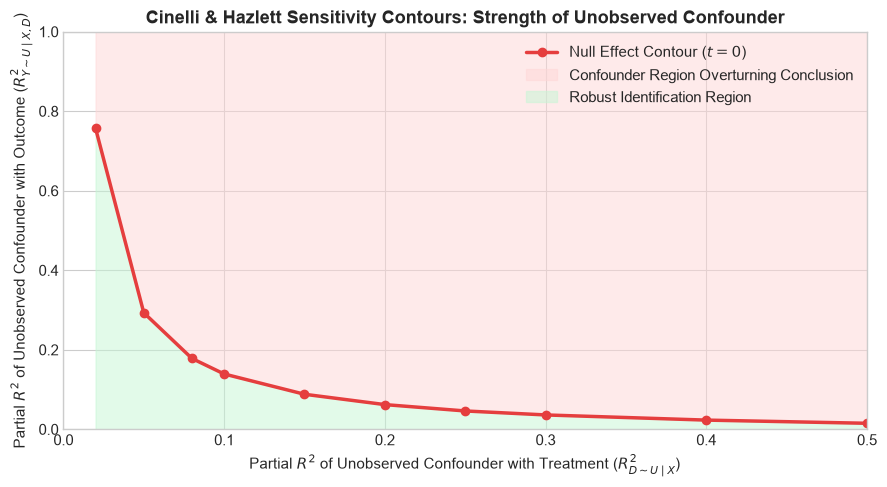

In [6]:
# Plot Cinelli & Hazlett Confounder Strength Contours
fig, ax = plt.subplots(figsize=(9, 5))

r2_d = [pt['r2_treatment'] for pt in cinelli['contour_points']]
r2_y = [pt['r2_outcome'] for pt in cinelli['contour_points']]

ax.plot(r2_d, r2_y, color='#E53E3E', marker='o', linewidth=2.5, label='Null Effect Contour ($t=0$)')
ax.fill_between(r2_d, r2_y, 1.0, color='#FED7D7', alpha=0.5, label='Confounder Region Overturning Conclusion')
ax.fill_between(r2_d, 0.0, r2_y, color='#C6F6D5', alpha=0.5, label='Robust Identification Region')

ax.set_title('Cinelli & Hazlett Sensitivity Contours: Strength of Unobserved Confounder', fontweight='bold')
ax.set_xlabel('Partial $R^2$ of Unobserved Confounder with Treatment ($R^2_{D \sim U \mid X}$)')
ax.set_ylabel('Partial $R^2$ of Unobserved Confounder with Outcome ($R^2_{Y \sim U \mid X, D}$)')
ax.set_xlim(0, 0.5)
ax.set_ylim(0, 1.0)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


## 4. Real-Time Streaming Data Simulation (30-Day Stream)

In production, consumer behaviour shifts over time. Using `src.optimizer.simulate_traffic_stream`, we simulate 30 consecutive days of incoming live traffic:
- **Days 1 - 14**: Normal baseline with seasonal weekly cycles.
- **Days 15 - 19**: Gradual inflation drift (rising average order values).
- **Day 20**: A **macroeconomic shock** (e.g. competitor flash sale or price hike) that shifts consumer price sensitivity and spend distributions.


In [7]:
# Simulate 30-day incoming event stream with macroeconomic shift at Day 20
stream_df = simulate_traffic_stream(
    base_df=reference_df,
    n_days=30,
    daily_records=120,
    inflation_rate=0.008,
    seasonal_period=7,
    drift_shock_day=20,
    random_state=42
)

print(f"Generated {len(stream_df):,} streaming records across {stream_df['day'].nunique()} days.")
stream_df[['day', 'date', 'past_spend', 'recency_days', 'category_affinity', 'discount', 'purchase']].tail(6)


Generated 3,600 streaming records across 30 days.


,day,date,past_spend,recency_days,category_affinity,discount,purchase
3594,30,2026-10-30,427.252109,42.5,0.891596,20,1
3595,30,2026-10-30,141.292753,211.5,0.683496,10,0
3596,30,2026-10-30,123.284280,31.5,0.427996,10,0
3597,30,2026-10-30,136.619021,281.5,0.289096,10,0
3598,30,2026-10-30,148.040453,281.5,0.574396,10,0
3599,30,2026-10-30,159.680966,92.5,0.721396,20,1


## 5. Continuous Rolling Window Drift Monitoring

We monitor statistical divergence between the streaming production distribution and the training baseline using a 7-day sliding window:
- **Population Stability Index (PSI)**:
  $$\text{PSI} = \sum_{k=1}^B (P_k - Q_k) \times \ln(P_k / Q_k)$$
  - $\text{PSI} < 0.10$: Healthy / Stable
  - $0.10 \le \text{PSI} < 0.20$: Moderate Shift
  - $\text{PSI} \ge 0.20$: Critical Drift $\to$ Automated Retraining Alert!
- **Wasserstein Distance**: Earth Mover's Distance capturing physical feature shift.
- **Kolmogorov-Smirnov (KS) Test**: Maximum empirical CDF divergence.


In [8]:
# Compute rolling window drift telemetry across 7-day windows
drift_results = compute_rolling_drift(
    stream_df=stream_df,
    reference_df=reference_df,
    window_size_days=7,
    psi_threshold=0.20
)

timeline_df = pd.DataFrame(drift_results['timeline'])
print(f"Overall Pipeline Status: {drift_results['overall_status']}")
print(f"Retraining Recommended: {drift_results['retrain_recommended']}")
if drift_results['first_trigger_day']:
    print(f"First Critical Drift Alert Triggered on: Day {drift_results['first_trigger_day']}")

timeline_df.tail(10)


Overall Pipeline Status: Retraining Triggered
Retraining Recommended: True
First Critical Drift Alert Triggered on: Day 24


,day,date,max_psi,avg_wasserstein,max_ks,alert_triggered,status,dominant_feature
14,21,2026-10-21,0.1203,5.2274,0.1639,False,Mild Shift,past_spend
15,22,2026-10-22,0.1476,5.9751,0.1841,False,Mild Shift,past_spend
16,23,2026-10-23,0.1669,6.4721,0.1960,False,Mild Shift,past_spend
17,24,2026-10-24,0.2158,7.2792,0.2163,True,Critical Drift,past_spend
18,25,2026-10-25,0.2439,8.0506,0.2277,True,Critical Drift,past_spend
19,26,2026-10-26,0.2543,8.2922,0.2301,True,Critical Drift,past_spend
20,27,2026-10-27,0.2777,8.6729,0.2394,True,Critical Drift,past_spend
21,28,2026-10-28,0.2526,8.1522,0.2238,True,Critical Drift,past_spend
22,29,2026-10-29,0.2667,8.5466,0.2234,True,Critical Drift,past_spend
23,30,2026-10-30,0.3191,9.0901,0.2470,True,Critical Drift,past_spend


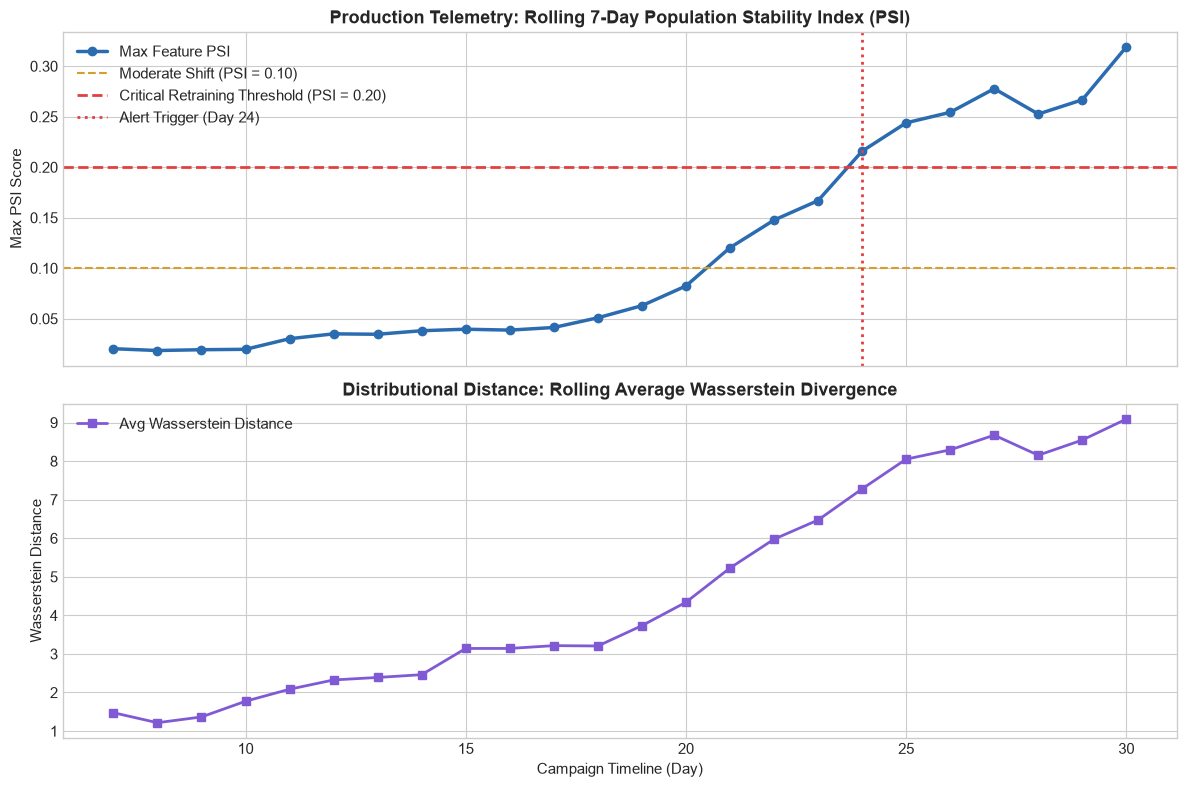

In [9]:
# Plot 1: 30-Day PSI Telemetry Timeline
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# PSI Plot
ax1 = axes[0]
ax1.plot(timeline_df['day'], timeline_df['max_psi'], color='#2B6CB0', marker='o', linewidth=2.5, label='Max Feature PSI')
ax1.axhline(0.10, color='#D69E2E', linestyle='--', linewidth=1.5, label='Moderate Shift (PSI = 0.10)')
ax1.axhline(0.20, color='#E53E3E', linestyle='--', linewidth=2.0, label='Critical Retraining Threshold (PSI = 0.20)')

if drift_results['first_trigger_day']:
    ax1.axvline(drift_results['first_trigger_day'], color='#E53E3E', linestyle=':', linewidth=2, label=f"Alert Trigger (Day {drift_results['first_trigger_day']})")

ax1.set_title('Production Telemetry: Rolling 7-Day Population Stability Index (PSI)', fontweight='bold')
ax1.set_ylabel('Max PSI Score')
ax1.legend(loc='upper left')

# Wasserstein Distance Plot
ax2 = axes[1]
ax2.plot(timeline_df['day'], timeline_df['avg_wasserstein'], color='#805AD5', marker='s', linewidth=2.0, label='Avg Wasserstein Distance')
ax2.set_title('Distributional Distance: Rolling Average Wasserstein Divergence', fontweight='bold')
ax2.set_ylabel('Wasserstein Distance')
ax2.set_xlabel('Campaign Timeline (Day)')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [10]:
# Automated Retraining Alerts Log
print("--- Automated Operational Drift Alerts Log ---")
if drift_results['alerts']:
    alert_df = pd.DataFrame(drift_results['alerts'])
    display(alert_df[['day', 'date', 'feature', 'metric', 'value', 'threshold', 'severity', 'message']].head(5))
else:
    print("No critical alerts triggered. System operating within normal tolerance.")


--- Automated Operational Drift Alerts Log ---


,day,date,feature,metric,value,threshold,severity,message
0,24,2026-10-24,past_spend,PSI,0.2158,0.2,Critical,Critical PSI drift of 0.2158 detected on past_...
1,25,2026-10-25,past_spend,PSI,0.2439,0.2,Critical,Critical PSI drift of 0.2439 detected on past_...
2,26,2026-10-26,past_spend,PSI,0.2543,0.2,Critical,Critical PSI drift of 0.2543 detected on past_...
3,27,2026-10-27,past_spend,PSI,0.2777,0.2,Critical,Critical PSI drift of 0.2777 detected on past_...
4,28,2026-10-28,past_spend,PSI,0.2526,0.2,Critical,Critical PSI drift of 0.2526 detected on past_...


## 💡 Production Governance Summary

### Comprehensive 4-Pillar Causal Stack:
1. **DAG Identification & Overlap Diagnostics** (`01_observational_data_confounding.ipynb`): Verified unconfoundedness and common support.
2. **Double Machine Learning Heterogeneity** (`02_double_machine_learning_uplift.ipynb`): Accurate customer-level CATE estimation via Neyman-orthogonal residualization.
3. **Prescriptive Mixed-Integer Optimization** (`03_budget_allocation_and_roi.ipynb`): Optimal MILP knapsack allocation with policy constraints and holdout of Sure Things.
4. **Causal Refutations & Live Drift Monitoring** (`04_refutation_and_drift_telemetry.ipynb`): Fail-safe production guardrails with continuous statistical telemetry and automated retraining triggers.

🚀 **The EconoCausal Walkthrough Suite is complete, rigorously validated, and production-ready!**
